In [1]:
print("hello")

hello


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


BASE_FOLDER = Path(
    r"C:\Users\pkmpp\Documents\GitHub\J26-DS-323\experiments\pasan\step by step\data"
)

DATASETS = {
    "5min": (
        BASE_FOLDER / "solar_5min_with_time_features_03 combine_wether_data_filtered.csv",
        5,
    ),
    "15min": (
        BASE_FOLDER / "solar_15min_with_time_features_03 combine_wether_data_filtered.csv",
        15,
    ),
}

REPORT_FOLDER = BASE_FOLDER / "analysis_with_time_features_06 analize"
REPORT_FOLDER.mkdir(parents=True, exist_ok=True)

TIME_FEATURES = [
    "time_of_day_sin",
    "time_of_day_cos",
    "day_of_year_sin",
    "day_of_year_cos",
]

FEATURES = [
    "power_w_per_kwp",
    "weather_temperature_c",
    "weather_relative_humidity_pct",
    "weather_wind_speed_ms",
    "weather_cloud_cover_pct",
    "weather_cloud_cover_low_pct",
    "weather_cloud_cover_mid_pct",
    "weather_cloud_cover_high_pct",
    "weather_ghi_instant_wm2",
    "weather_dni_instant_wm2",
    "weather_dhi_instant_wm2",
    "weather_preceding_hour_precipitation_mm",
    "weather_preceding_hour_rain_mm",
    "sun_elevation_deg",
    "sun_azimuth_sin",
    "sun_azimuth_cos",
    "latitude",
    "longitude",
    "pv_capacity_kwp",
    *TIME_FEATURES,
]


def expected_time_features(local_time):
    minutes = (
        local_time.dt.hour * 60
        + local_time.dt.minute
    )

    daily_angle = 2 * np.pi * minutes / 1440

    days_in_year = np.where(
        local_time.dt.is_leap_year, 366, 365
    )

    yearly_angle = (
        2 * np.pi
        * (local_time.dt.dayofyear - 1)
        / days_in_year
    )

    return {
        "time_of_day_sin": np.sin(daily_angle),
        "time_of_day_cos": np.cos(daily_angle),
        "day_of_year_sin": np.sin(yearly_angle),
        "day_of_year_cos": np.cos(yearly_angle),
    }


def analyze_dataset(path, label, interval_minutes):
    output = REPORT_FOLDER / label
    output.mkdir(parents=True, exist_ok=True)

    header = pd.read_csv(
        path, nrows=0, encoding="utf-8-sig"
    ).columns.tolist()

    required = {
        "inverterSn",
        "timestamp_5min",
        "pac",
        "pv_capacity_kwp",
        "power_w_per_kwp",
        *TIME_FEATURES,
    }

    missing = required - set(header)

    if missing:
        raise ValueError(
            f"{label}: missing columns {sorted(missing)}"
        )

    # Load only columns used by this analysis.
    selected = list(dict.fromkeys([
        "inverterSn",
        "timestamp_5min",
        "pac",
        *[column for column in FEATURES if column in header],
        *[
            column for column in [
                "town",
                "weather_matched",
                "weather_features_complete",
            ]
            if column in header
        ],
    ]))

    df = pd.read_csv(
        path,
        usecols=selected,
        dtype={"inverterSn": "string"},
        encoding="utf-8-sig",
    )

    if df.empty:
        raise ValueError(f"{label}: dataset is empty")

    numeric_columns = list(dict.fromkeys([
        "pac",
        *[column for column in FEATURES if column in df],
    ]))

    for column in numeric_columns:
        df[column] = pd.to_numeric(
            df[column], errors="raise"
        )

    # Report missing cells before adding analysis helpers.
    missing_report = pd.DataFrame({
        "column": df.columns,
        "missing_count": df.isna().sum().to_numpy(),
        "missing_percent": (
            df.isna().mean().to_numpy() * 100
        ),
    })

    missing_report.to_csv(
        output / "missing_values.csv", index=False
    )

    df["_time"] = pd.to_datetime(
        df["timestamp_5min"],
        utc=True,
        format="mixed",
        errors="raise",
    ).dt.tz_convert("Asia/Colombo")

    if df["_time"].isna().any():
        raise ValueError(f"{label}: missing timestamps")

    df["_date"] = df["_time"].dt.date

    checks = {
        "rows": len(df),
        "inverters": df["inverterSn"].nunique(),
        "missing_inverter_ids": int(
            df["inverterSn"].isna().sum()
        ),
        "duplicate_device_times": int(
            df.duplicated(["inverterSn", "_time"]).sum()
        ),
        "timestamps_off_grid": int(
            df["_time"].ne(
                df["_time"].dt.floor(
                    f"{interval_minutes}min"
                )
            ).sum()
        ),
        "missing_power": int(df["pac"].isna().sum()),
        "nonfinite_power": int(
            (~np.isfinite(df["pac"])).sum()
        ),
        "negative_power": int(df["pac"].lt(0).sum()),
        "zero_power": int(df["pac"].eq(0).sum()),
        "invalid_capacity": int((
            ~np.isfinite(df["pv_capacity_kwp"])
            | df["pv_capacity_kwp"].le(0)
        ).sum()),
    }

    # Verify the newly added cyclic features.
    expected = expected_time_features(df["_time"])

    for column in TIME_FEATURES:
        values = df[column]

        checks[f"{column}_outside_range"] = int(
            (~values.between(-1.00000001, 1.00000001)).sum()
        )

        checks[f"{column}_calculation_mismatches"] = int(
            (~np.isclose(
                values,
                expected[column],
                rtol=1e-7,
                atol=1e-7,
                equal_nan=False,
            )).sum()
        )

    valid_normalization = (
        np.isfinite(df["pac"])
        & np.isfinite(df["pv_capacity_kwp"])
        & df["pv_capacity_kwp"].gt(0)
    )

    checks["normalization_mismatches"] = int(
        (~np.isclose(
            df.loc[valid_normalization, "power_w_per_kwp"],
            (
                df.loc[valid_normalization, "pac"]
                / df.loc[valid_normalization, "pv_capacity_kwp"]
            ),
            rtol=1e-6,
            atol=1e-6,
        )).sum()
    )

    quality = pd.DataFrame(
        checks.items(), columns=["check", "value"]
    )

    quality.to_csv(
        output / "quality_summary.csv", index=False
    )

    df[numeric_columns].describe(
        percentiles=[0.01, 0.5, 0.95, 0.99]
    ).T.to_csv(output / "numeric_summary.csv")

    print(f"\n{label} dataset")
    print("Date range:", df["_time"].min(), "to", df["_time"].max())
    display(quality)

    display(
        missing_report.loc[
            missing_report["missing_count"].gt(0)
        ]
    )

    if checks["missing_inverter_ids"]:
        raise ValueError("Resolve missing inverter IDs")

    if checks["duplicate_device_times"]:
        raise ValueError("Resolve duplicate device/time pairs")

    if checks["timestamps_off_grid"]:
        raise ValueError("Resolve timestamps outside the expected grid")

    # Device summaries.
    device_summary = df.groupby("inverterSn").agg(
        rows=("pac", "size"),
        first_timestamp=("_time", "min"),
        last_timestamp=("_time", "max"),
        recorded_days=("_date", "nunique"),
        capacity_kwp=("pv_capacity_kwp", "first"),
        capacity_value_count=("pv_capacity_kwp", "nunique"),
        peak_power_w=("pac", "max"),
        peak_normalized_w_per_kwp=("power_w_per_kwp", "max"),
        zero_power_percent=(
            "pac", lambda values: values.eq(0).mean() * 100
        ),
        normalized_above_1000_count=(
            "power_w_per_kwp",
            lambda values: values.gt(1000).sum(),
        ),
    )

    if "town" in df:
        device_summary["town"] = (
            df.groupby("inverterSn")["town"].first()
        )

    device_summary.to_csv(
        output / "device_summary.csv"
    )

    df.loc[
        df["power_w_per_kwp"].gt(1000)
    ].to_csv(
        output / "normalized_above_1000_for_review.csv",
        index=False,
    )

    # Exclude the slot starting at 19:00 from interval coverage.
    minutes = (
        df["_time"].dt.hour * 60
        + df["_time"].dt.minute
    )

    study = df.loc[
        minutes.ge(6 * 60)
        & minutes.lt(19 * 60)
    ].copy()

    daily = study.groupby(
        ["inverterSn", "_date"]
    ).agg(
        recorded_slots=("pac", "size"),
        finite_power_slots=(
            "pac",
            lambda values: np.isfinite(values).sum(),
        ),
    )

    calendar_keys = []

    for inverter_sn, group in df.groupby("inverterSn"):
        dates = pd.date_range(
            min(group["_date"]),
            max(group["_date"]),
            freq="D",
        ).date

        calendar_keys.extend(
            (inverter_sn, day) for day in dates
        )

    calendar_index = pd.MultiIndex.from_tuples(
        calendar_keys,
        names=["inverterSn", "_date"],
    )

    daily = daily.reindex(calendar_index)

    for column in ["recorded_slots", "finite_power_slots"]:
        daily[column] = (
            daily[column].fillna(0).astype(int)
        )

    daily["expected_slots"] = (
        13 * 60 // interval_minutes
    )

    daily["recorded_slot_coverage_percent"] = (
        daily["recorded_slots"]
        / daily["expected_slots"]
        * 100
    )

    daily.to_csv(
        output / "daily_recorded_slot_coverage.csv"
    )

    # Correlation includes the four new time features.
    correlation_columns = [
        column for column in FEATURES if column in df
    ]

    correlations = (
        df[correlation_columns]
        .replace([np.inf, -np.inf], np.nan)
        .corr()
    )

    correlations.to_csv(
        output / "feature_correlations.csv"
    )

    return df, device_summary, daily, correlations, output

In [3]:
def save_plot(output_folder, filename):
    plt.tight_layout()
    plt.savefig(
        output_folder / filename,
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()


def create_plots(df, device_summary, daily, correlations, output, label):
    # 1. Generation distribution.
    plt.figure(figsize=(10, 4))

    values = (
        df["power_w_per_kwp"]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    plt.hist(values, bins=100)
    plt.xlabel("Power per installed capacity (W/kWp)")
    plt.ylabel("Rows")
    plt.title(f"{label}: capacity-normalized generation")

    save_plot(output, "normalized_generation_distribution.png")

    # 2. Peak generation per inverter.
    peaks = device_summary[
        "peak_normalized_w_per_kwp"
    ].sort_values()

    plt.figure(figsize=(13, 5))
    peaks.plot(kind="bar")

    plt.axhline(
        1000,
        color="red",
        linestyle="--",
        label="1,000 W/kWp: review reference",
    )

    plt.xlabel("Inverter serial number")
    plt.ylabel("Maximum normalized power (W/kWp)")
    plt.xticks(rotation=90, fontsize=6)
    plt.title(f"{label}: inverter peaks")
    plt.legend()

    save_plot(output, "normalized_peaks_by_inverter.png")

    # 3. Recorded-slot coverage.
    coverage = daily[
        "recorded_slot_coverage_percent"
    ].unstack("_date")

    fig, ax = plt.subplots(figsize=(14, 7))

    image = ax.imshow(
        np.ma.masked_invalid(
            coverage.to_numpy(dtype=float)
        ),
        aspect="auto",
        interpolation="nearest",
        vmin=0,
        vmax=100,
        cmap="viridis",
    )

    ax.set_yticks(range(len(coverage.index)))
    ax.set_yticklabels(coverage.index, fontsize=6)

    positions = np.unique(
        np.linspace(
            0,
            len(coverage.columns) - 1,
            min(10, len(coverage.columns)),
        ).astype(int)
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(
        [str(coverage.columns[i]) for i in positions],
        rotation=45,
        ha="right",
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Inverter")
    ax.set_title(f"{label}: recorded-slot coverage")
    fig.colorbar(image, ax=ax, label="Coverage (%)")

    save_plot(output, "daily_coverage_heatmap.png")

    # 4. Correlation heatmap with time features.
    fig, ax = plt.subplots(figsize=(15, 13))

    image = ax.imshow(
        np.ma.masked_invalid(correlations.to_numpy()),
        vmin=-1,
        vmax=1,
        cmap="coolwarm",
    )

    names = correlations.columns.tolist()

    ax.set_xticks(range(len(names)))
    ax.set_yticks(range(len(names)))
    ax.set_xticklabels(names, rotation=90, fontsize=8)
    ax.set_yticklabels(names, fontsize=8)

    ax.set_title(
        f"{label}: exploratory Pearson correlations"
    )

    fig.colorbar(image, ax=ax, label="Correlation")

    save_plot(output, "feature_correlations_with_time.png")

    # 5. Verify the daily sine/cosine cycle visually.
    times = np.arange(0, 1440, 15)
    angle = 2 * np.pi * times / 1440

    plt.figure(figsize=(10, 4))
    plt.plot(times / 60, np.sin(angle), label="time_of_day_sin")
    plt.plot(times / 60, np.cos(angle), label="time_of_day_cos")
    plt.xlabel("Sri Lankan local time: hour")
    plt.ylabel("Feature value")
    plt.title("Daily cyclic time encoding")
    plt.xticks(np.arange(0, 25, 3))
    plt.legend()

    save_plot(output, "daily_time_feature_cycle.png")

    # 6. Seasonal sine/cosine cycle.
    days = np.arange(365)
    angle = 2 * np.pi * days / 365

    plt.figure(figsize=(10, 4))
    plt.plot(days + 1, np.sin(angle), label="day_of_year_sin")
    plt.plot(days + 1, np.cos(angle), label="day_of_year_cos")
    plt.xlabel("Day of year in a non-leap year")
    plt.ylabel("Feature value")
    plt.title("Annual cyclic time encoding")
    plt.legend()

    save_plot(output, "annual_time_feature_cycle.png")

    # 7. Observed generation pattern by local time.
    # These pooled means reflect unequal device and date coverage.
    plot_data = df.copy()
    plot_data["_minute_of_day"] = (
        plot_data["_time"].dt.hour * 60
        + plot_data["_time"].dt.minute
    )

    time_profile = plot_data.groupby(
        "_minute_of_day"
    )["power_w_per_kwp"].mean()

    plt.figure(figsize=(10, 4))
    plt.plot(
        time_profile.index / 60,
        time_profile.values,
    )

    plt.xlabel("Sri Lankan local time: hour")
    plt.ylabel("Mean normalized power (W/kWp)")
    plt.title(f"{label}: pooled generation by time of day")

    save_plot(output, "generation_by_time_of_day.png")


5min dataset
Date range: 2023-09-19 11:45:00+05:30 to 2026-08-01 19:00:00+05:30


,check,value
0,rows,2301330
1,inverters,42
2,missing_inverter_ids,0
3,duplicate_device_times,0
4,timestamps_off_grid,0
5,missing_power,0
6,nonfinite_power,0
7,negative_power,0
8,zero_power,7528
9,invalid_capacity,0


,column,missing_count,missing_percent


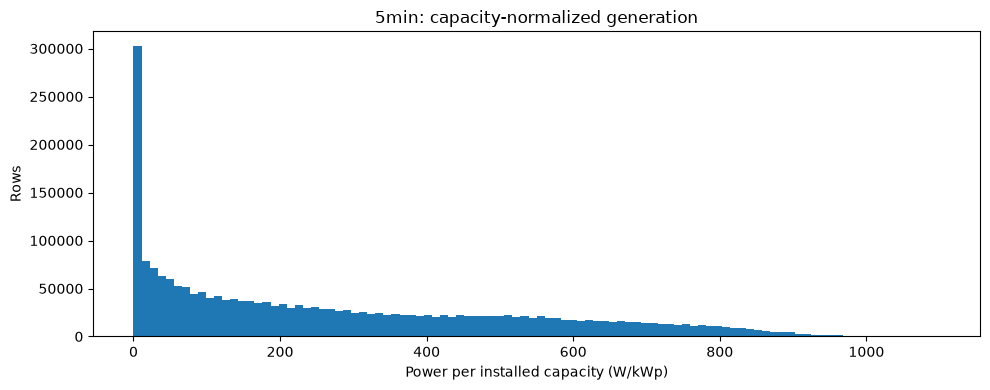

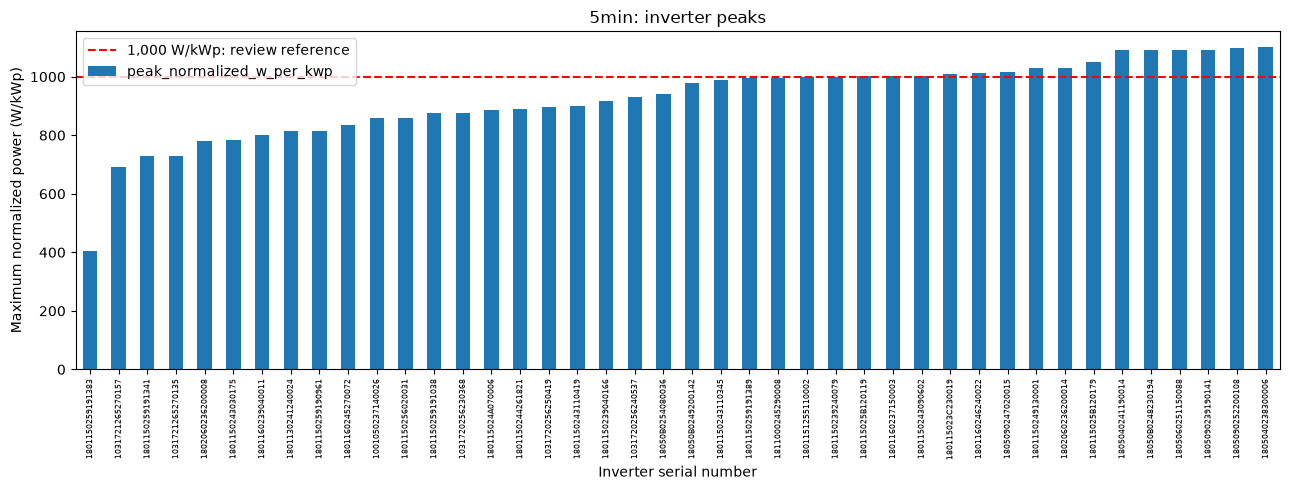

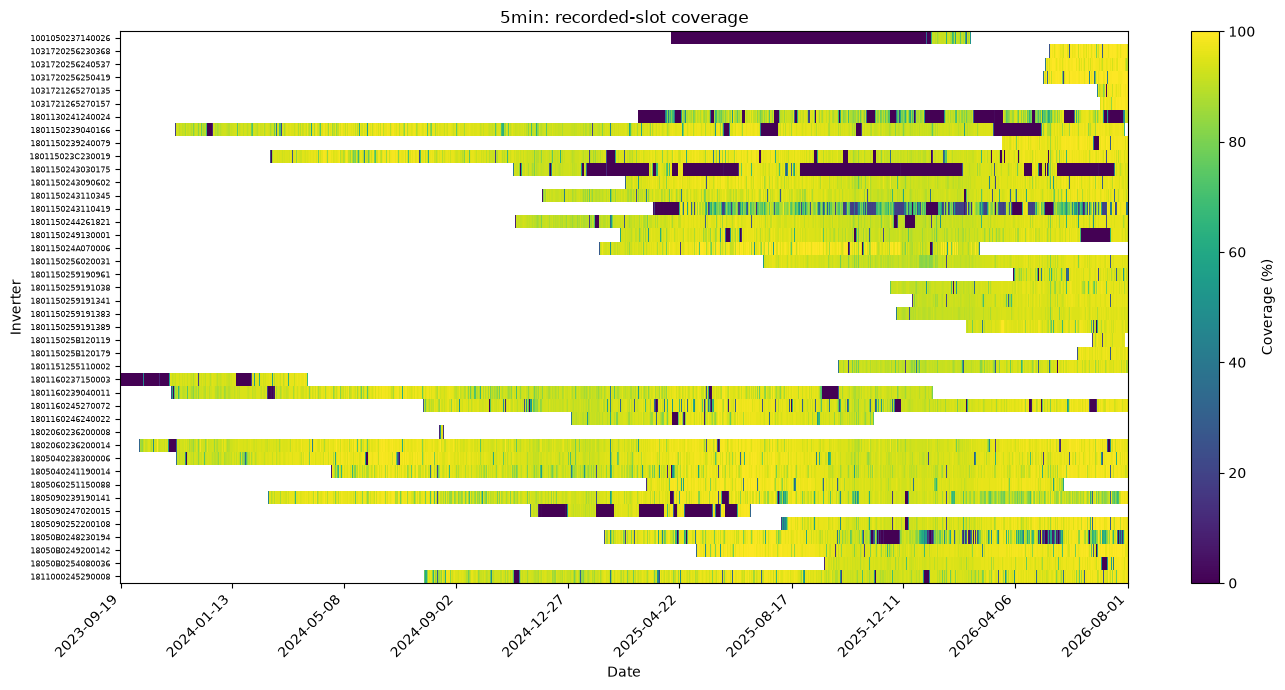

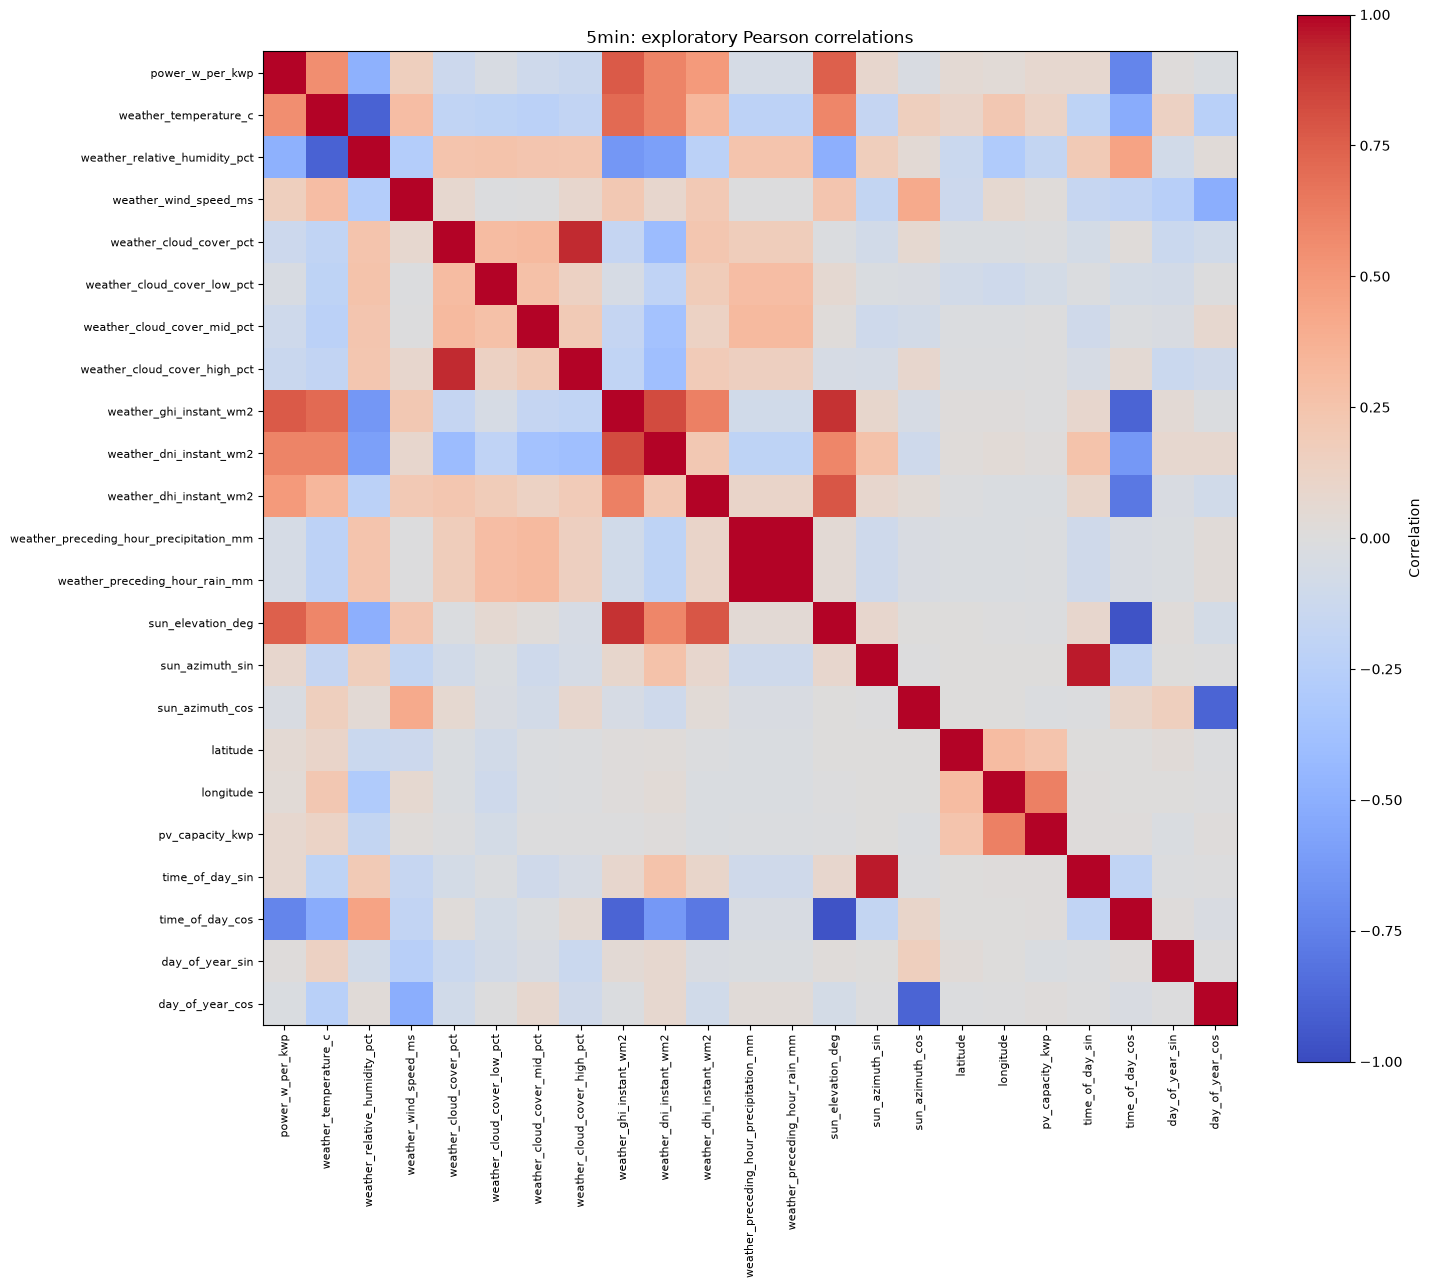

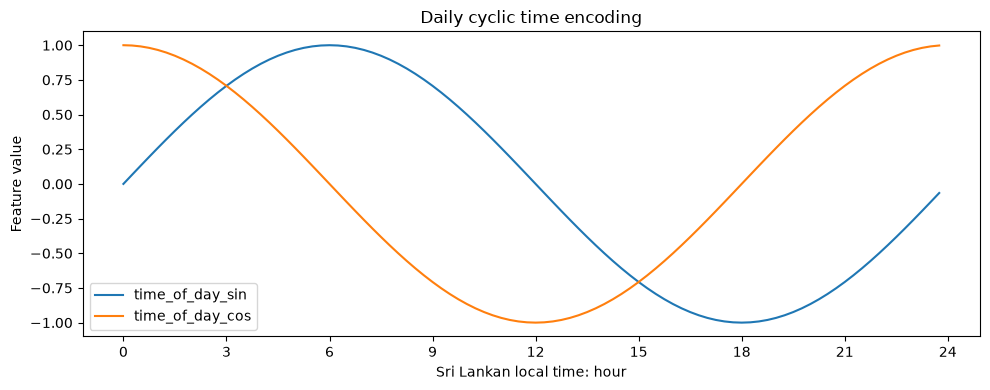

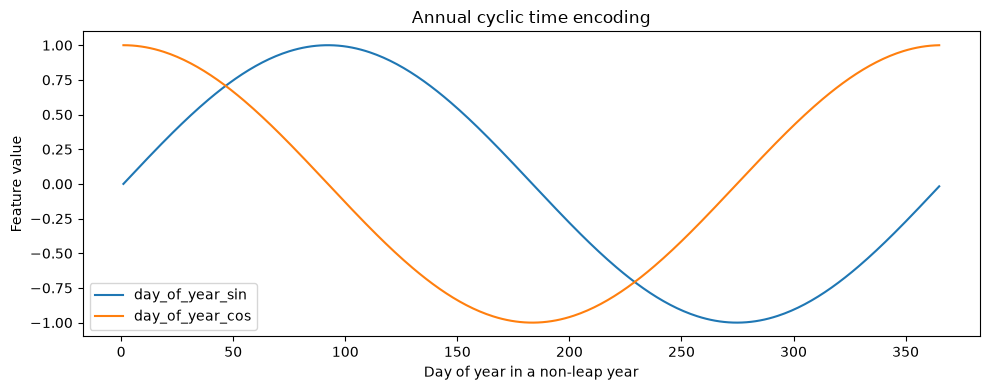

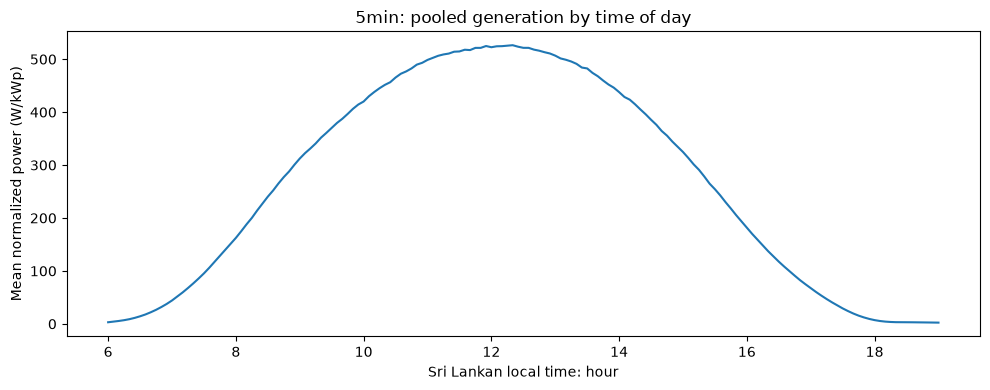


15min dataset
Date range: 2023-09-19 11:45:00+05:30 to 2026-08-01 19:00:00+05:30


,check,value
0,rows,767779
1,inverters,42
2,missing_inverter_ids,0
3,duplicate_device_times,0
4,timestamps_off_grid,0
5,missing_power,0
6,nonfinite_power,0
7,negative_power,0
8,zero_power,1660
9,invalid_capacity,0


,column,missing_count,missing_percent


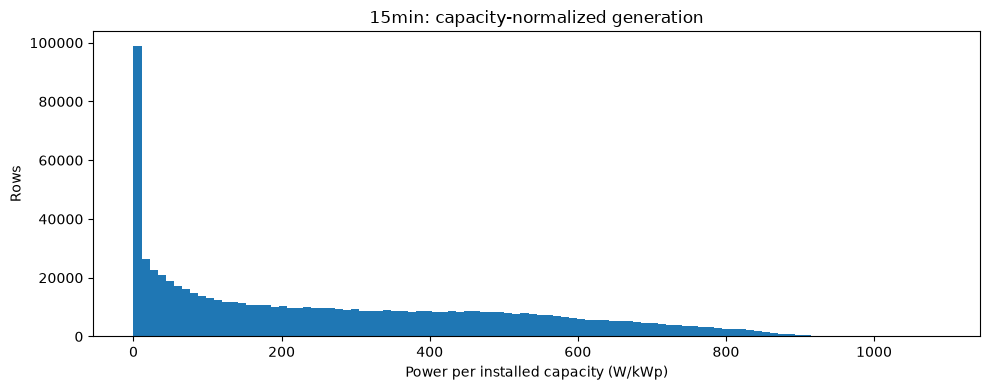

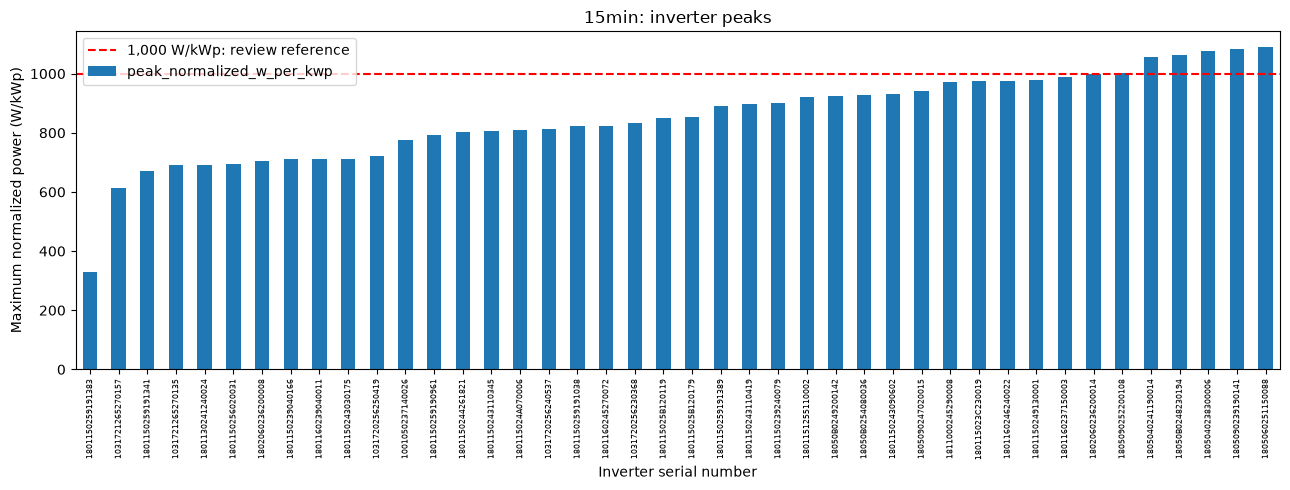

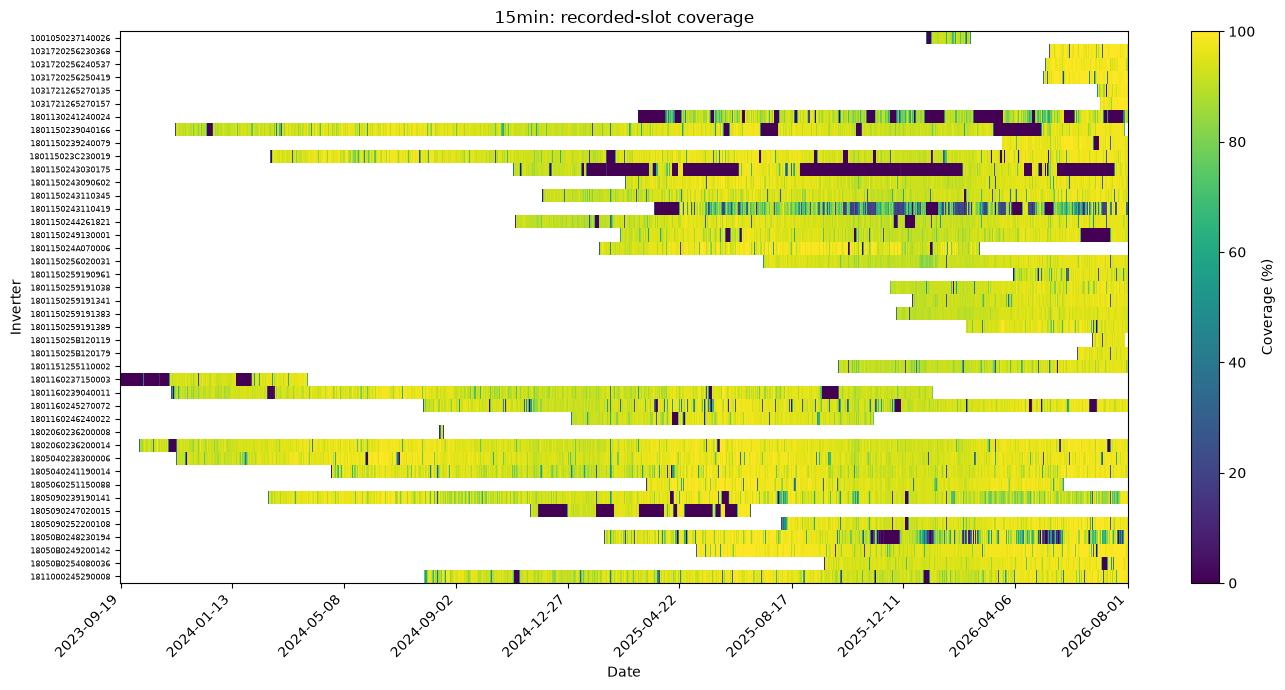

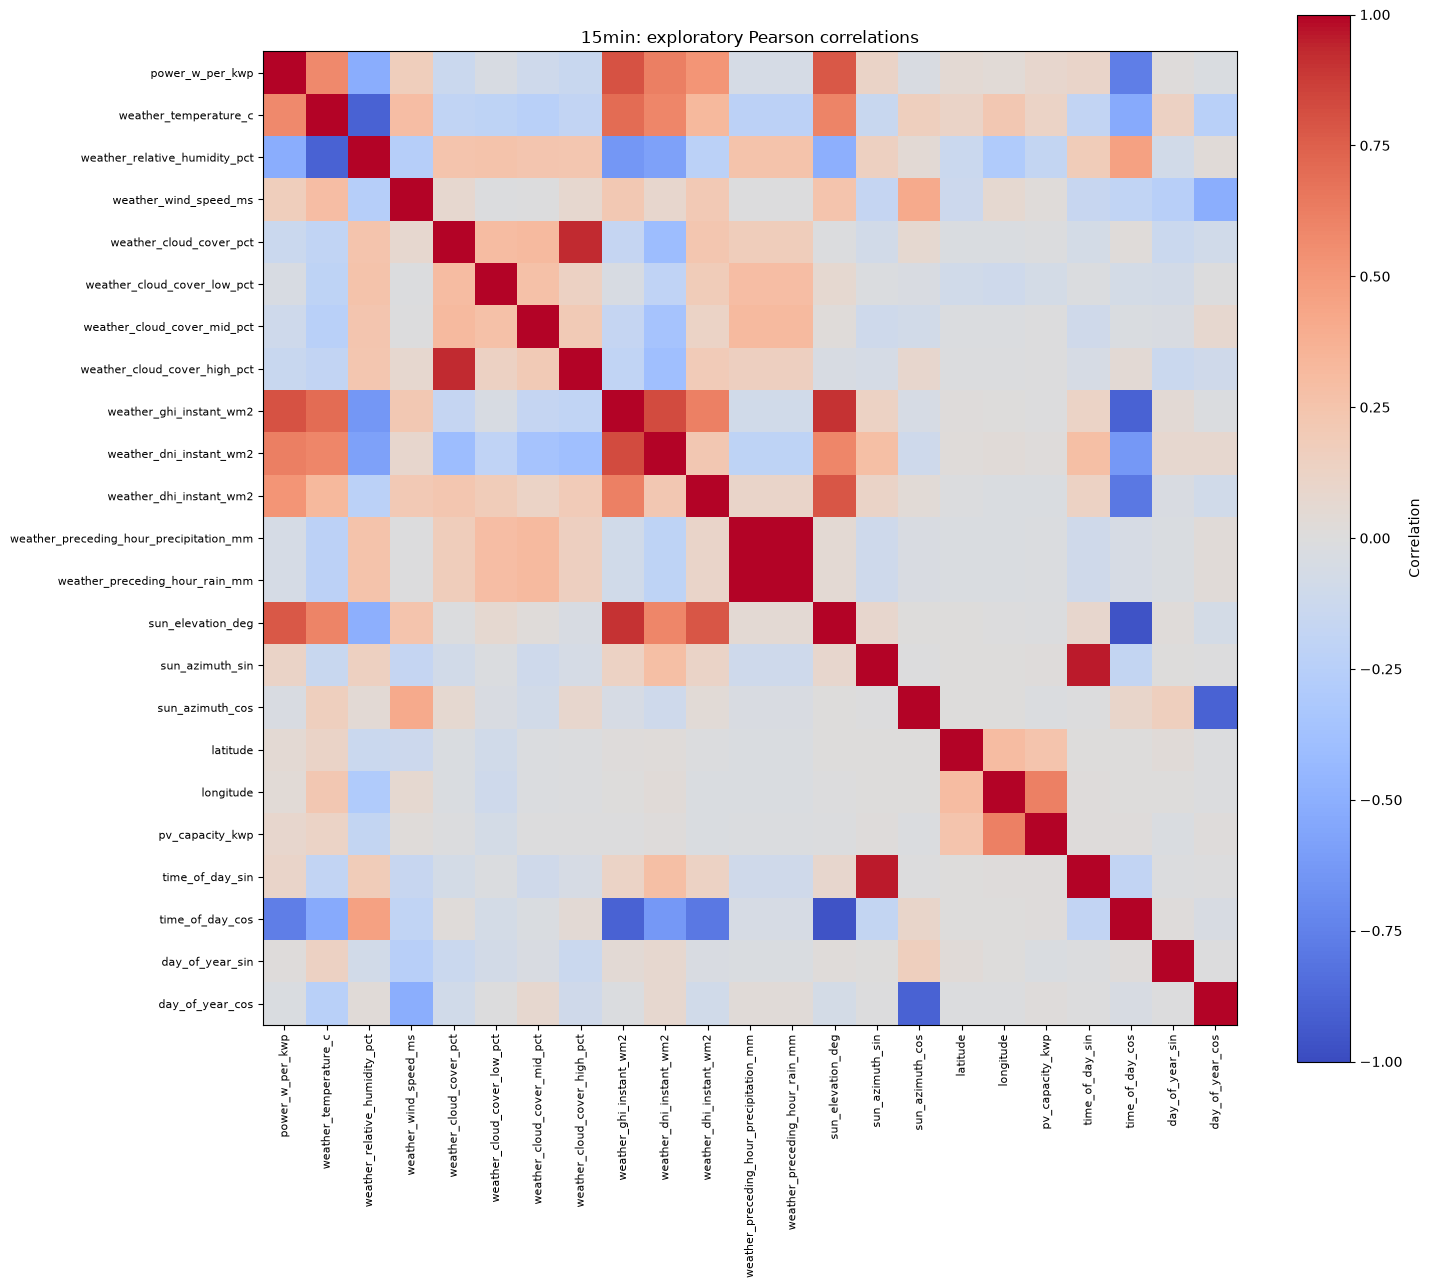

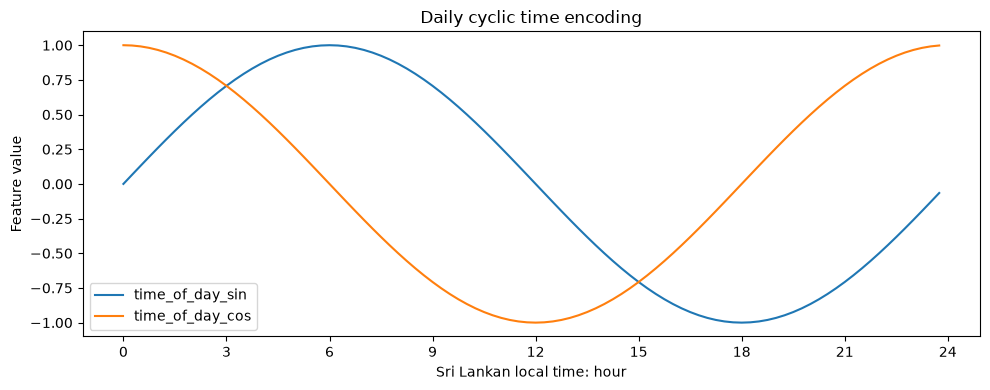

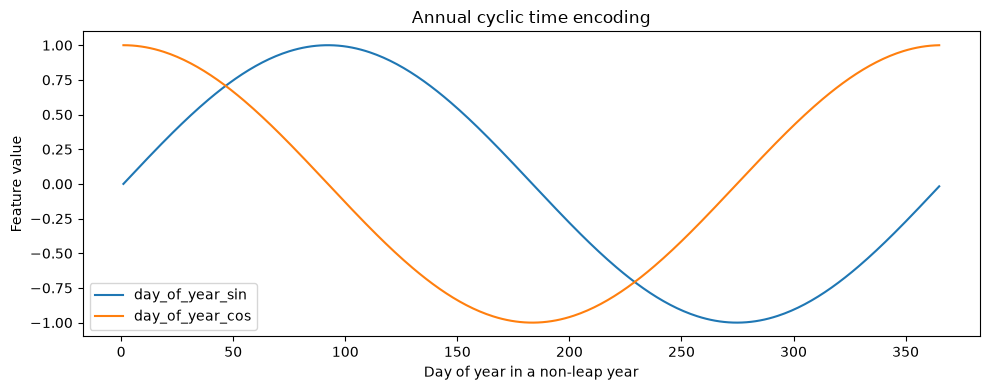

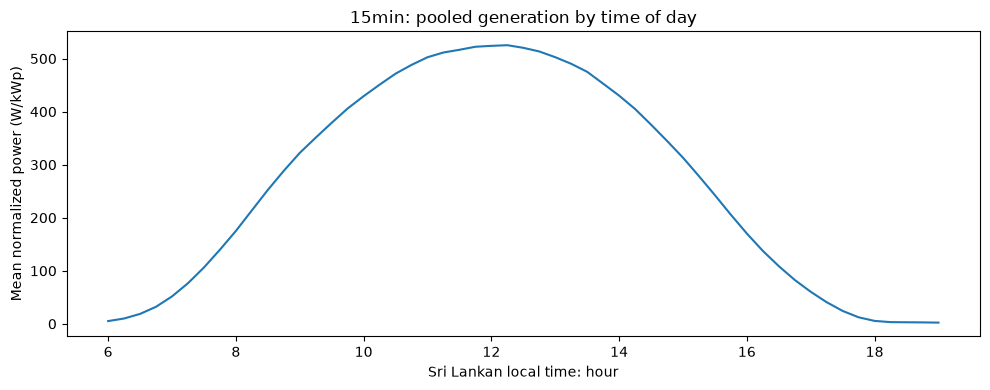

,dataset,rows,inverters,first_timestamp,last_timestamp,zero_power_percent,normalized_power_max,time_feature_missing_cells
0,5min,2301330,42,2023-09-19 11:45:00+05:30,2026-08-01 19:00:00+05:30,0.327115,1100.000000,0
1,15min,767779,42,2023-09-19 11:45:00+05:30,2026-08-01 19:00:00+05:30,0.216208,1088.666667,0


Reports saved to: C:\Users\pkmpp\Documents\GitHub\J26-DS-323\experiments\pasan\step by step\data\analysis_with_time_features_06 analize


In [4]:
comparison_rows = []

for label, (path, interval_minutes) in DATASETS.items():
    if not path.is_file():
        raise FileNotFoundError(path)

    df, device_summary, daily, correlations, output = analyze_dataset(
        path,
        label,
        interval_minutes,
    )

    create_plots(
        df,
        device_summary,
        daily,
        correlations,
        output,
        label,
    )

    comparison_rows.append({
        "dataset": label,
        "rows": len(df),
        "inverters": df["inverterSn"].nunique(),
        "first_timestamp": df["_time"].min(),
        "last_timestamp": df["_time"].max(),
        "zero_power_percent": df["pac"].eq(0).mean() * 100,
        "normalized_power_max": df["power_w_per_kwp"].max(),
        "time_feature_missing_cells": int(
            df[TIME_FEATURES].isna().sum().sum()
        ),
    })

    # Release the large dataset before loading the next one.
    del df, device_summary, daily, correlations

comparison = pd.DataFrame(comparison_rows)

comparison.to_csv(
    REPORT_FOLDER / "dataset_comparison.csv",
    index=False,
)

display(comparison)

print("Reports saved to:", REPORT_FOLDER)